# 03 — Tuning, Model Selection, and Final Evaluation

This notebook documents the saved tuning and evaluation results:

- model selection uses **5-fold CV on the training set only**;
- the test set is evaluated **once**, after the model is selected;
- all metrics are in IDR and come from the real experiment, not placeholders.

The notebook loads the artifacts produced by `src/train.py --tune` and
`src/train.py --evaluate`; it does not re-evaluate the test set.

In [1]:
import json
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd()
while not (PROJECT_ROOT / "pyproject.toml").exists():
    if PROJECT_ROOT == PROJECT_ROOT.parent:
        raise RuntimeError("Project root not found")
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import joblib
import pandas as pd
from sklearn.model_selection import KFold, cross_validate

from src.train import (
    CV_FOLDS,
    FEATURES,
    MODEL_PATH,
    RANDOM_STATE,
    SCORERS,
    TUNING_PATH,
    METRICS_PATH,
    load_data,
    split_data,
)

pd.set_option("display.width", 220)

tuning = json.loads(TUNING_PATH.read_text())
metrics = json.loads(METRICS_PATH.read_text())
selected = tuning["selected"]

print("Selected model:", selected["name"])
print("Best params:", selected["best_params"])
print("Test used during tuning:", tuning["test_evaluated"])
print(f"Rows: {metrics['n_samples']:,} | train: {metrics['n_train']:,} | test: {metrics['n_test']:,}")

Selected model: gradient_boosting_tuned
Best params: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 400, 'subsample': 0.8}
Test used during tuning: False
Rows: 9,401 | train: 7,520 | test: 1,881


## Grid search results

In [2]:
for search_name in ("random_forest", "gradient_boosting"):
    search = tuning["searches"][search_name]
    print(f"\n{search_name}")
    print("  candidates:", search["n_candidates"], "| fits:", search["n_fits"])
    print("  best params:", search["best_params"])
    print(
        "  best CV MAE:",
        f"Rp{search['cv_metrics']['mae']['mean']:,.0f}",
        "| CV RMSE:",
        f"Rp{search['cv_metrics']['rmse']['mean']:,.0f}",
        "| CV R2:",
        f"{search['cv_metrics']['r2']['mean']:.4f}",
    )

candidates = pd.DataFrame(
    {
        "cv_mae": {name: values["mae"]["mean"] for name, values in tuning["candidates"].items()},
        "cv_rmse": {name: values["rmse"]["mean"] for name, values in tuning["candidates"].items()},
        "cv_r2": {name: values["r2"]["mean"] for name, values in tuning["candidates"].items()},
    }
).sort_values("cv_mae")
display(candidates)


random_forest
  candidates: 18 | fits: 91
  best params: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'n_estimators': 500}
  best CV MAE: Rp4,461,671,000 | CV RMSE: Rp15,429,244,368 | CV R2: 0.4249

gradient_boosting
  candidates: 16 | fits: 81
  best params: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 400, 'subsample': 0.8}
  best CV MAE: Rp4,370,866,728 | CV RMSE: Rp14,905,937,070 | CV R2: 0.4620


,cv_mae,cv_rmse,cv_r2
gradient_boosting_tuned,4.370867e+09,1.490594e+10,0.462011
random_forest_tuned,4.461671e+09,1.542924e+10,0.424910
ridge,4.671027e+09,1.544705e+10,0.417556
dummy,7.541253e+09,2.086020e+10,-0.083791


## Reproduce the selected model's CV score

In [3]:
df = load_data()
X_train, _, y_train, _ = split_data(df)
cv = KFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
model = joblib.load(MODEL_PATH)

scores = cross_validate(model, X_train, y_train, cv=cv, scoring=SCORERS, n_jobs=1)
reproduced = {
    "mae": float(-scores["test_mae"].mean()),
    "rmse": float(-scores["test_rmse"].mean()),
    "r2": float(scores["test_r2"].mean()),
}

comparison = pd.DataFrame(
    {
        "saved_cv": {
            "mae": selected["cv_metrics"]["mae"]["mean"],
            "rmse": selected["cv_metrics"]["rmse"]["mean"],
            "r2": selected["cv_metrics"]["r2"]["mean"],
        },
        "reproduced_cv": reproduced,
    }
)
comparison["abs_diff"] = (comparison["saved_cv"] - comparison["reproduced_cv"]).abs()
display(comparison)
print("Cross-validation only; test data was not used.")

,saved_cv,reproduced_cv,abs_diff
mae,4.370867e+09,4.370867e+09,0.0
rmse,1.490594e+10,1.490594e+10,0.0
r2,4.620113e-01,4.620113e-01,0.0


Cross-validation only; test data was not used.


## Overfitting check: train vs CV vs test

In [4]:
train_metrics = metrics["model"]["train_metrics"]
test_metrics = metrics["test_metrics"]

overfitting = pd.DataFrame(
    {
        "MAE": [train_metrics["mae"], selected["cv_metrics"]["mae"]["mean"], test_metrics["mae"]],
        "RMSE": [train_metrics["rmse"], selected["cv_metrics"]["rmse"]["mean"], test_metrics["rmse"]],
        "R2": [train_metrics["r2"], selected["cv_metrics"]["r2"]["mean"], test_metrics["r2"]],
    },
    index=["Train", "CV (training set)", "Test"],
)
display(overfitting)

print(
    "Test MAE gap over train:",
    f"Rp{metrics['train_vs_test']['mae_gap']:,.0f}",
)
print("Test R2 gap below train:", f"{metrics['train_vs_test']['r2_gap']:.4f}")

,MAE,RMSE,R2
Train,3.618904e+09,1.017464e+10,0.755528
CV (training set),4.370867e+09,1.490594e+10,0.462011
Test,4.579679e+09,1.339720e+10,0.521458


Test MAE gap over train: Rp960,774,859
Test R2 gap below train: 0.2341


The selected model fits the training data better than validation/test data, so some
overfitting remains. The test scores are still clearly better than the Dummy baseline,
and the CV/test gap is consistent with a model that has learned real signal rather than
only noise. Test metrics below are loaded from the single final evaluation.

## Error analysis

In [5]:
city_errors = pd.DataFrame(metrics["error_by_city"]).T
city_errors = city_errors.astype({"n": int, "mae": float, "rmse": float, "median_abs_error": float})
display(city_errors.sort_values("mae", ascending=False))

band_errors = pd.DataFrame(metrics["error_by_price_band"]).T
band_errors = band_errors.astype({"n": int, "mae": float, "rmse": float, "median_abs_error": float})
display(band_errors)

,n,mae,rmse,median_abs_error
Jakarta Pusat,119,1.110626e+10,2.257386e+10,2.696230e+09
Jakarta Selatan,645,8.491036e+09,2.023441e+10,3.322032e+09
Jakarta Utara,331,2.561812e+09,5.080845e+09,1.251538e+09
Jakarta Barat,481,1.381487e+09,2.655317e+09,6.570584e+08
Jakarta Timur,305,9.952704e+08,1.766585e+09,6.078110e+08


,n,mae,rmse,median_abs_error
<1B,68,4.732704e+08,1.038235e+09,2.674482e+08
1-3B,555,7.639218e+08,1.420932e+09,5.129918e+08
3-5B,363,1.264695e+09,2.032631e+09,8.141406e+08
5-10B,403,2.575157e+09,3.720319e+09,1.851466e+09
10-30B,347,6.391449e+09,8.423446e+09,5.140202e+09
>30B,145,3.064491e+10,4.584220e+10,1.890737e+10


## Permutation importance

In [6]:
importance = pd.DataFrame(
    {
        "increase_in_mae_idr": {
            feature: values["mean"] for feature, values in metrics["feature_importance"].items()
        },
        "std_idr": {
            feature: values["std"] for feature, values in metrics["feature_importance"].items()
        },
    }
).sort_values("increase_in_mae_idr", ascending=False)

importance["increase_in_mae_billion"] = importance["increase_in_mae_idr"] / 1e9
importance["std_billion"] = importance["std_idr"] / 1e9
display(importance[["increase_in_mae_billion", "std_billion"]])

print(metrics["feature_importance_note"])

,increase_in_mae_billion,std_billion
building_area,4.504011,0.122950
city,1.017754,0.081902
carport,0.539387,0.025773
bed_rooms,0.404438,0.048140
bath_rooms,0.183899,0.027529


Permutation importance on the test set, computed after model selection for interpretation only; not used to choose the model.


## Final evaluation figures

11_actual_vs_predicted.png


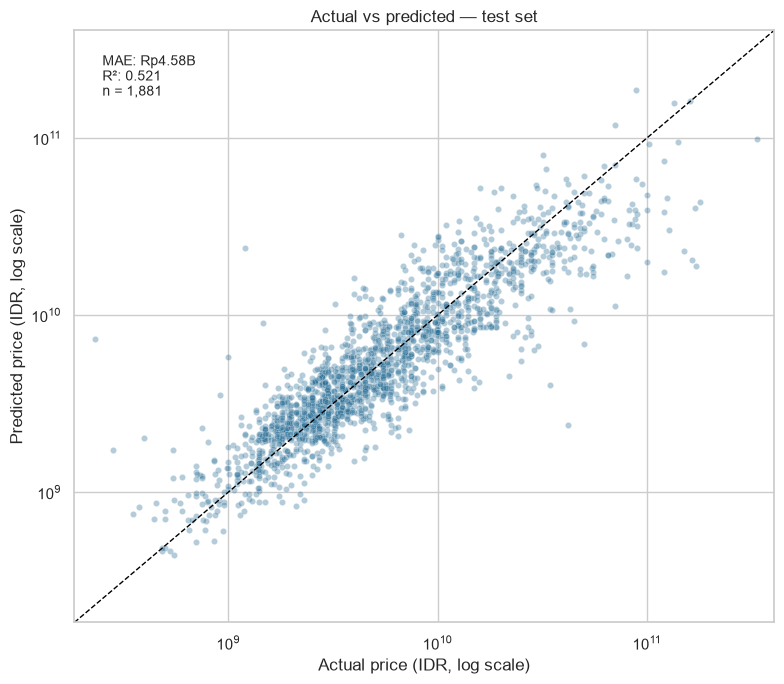

12_residuals.png


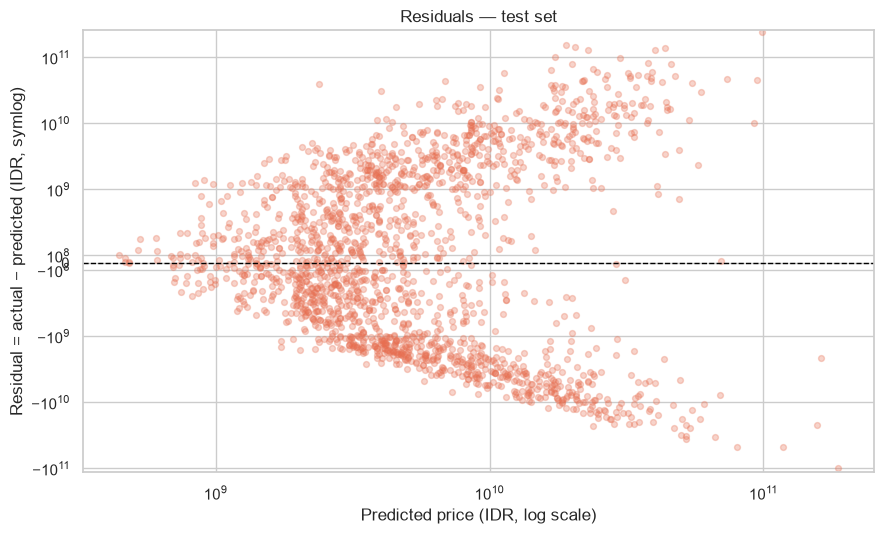

14_error_by_city.png


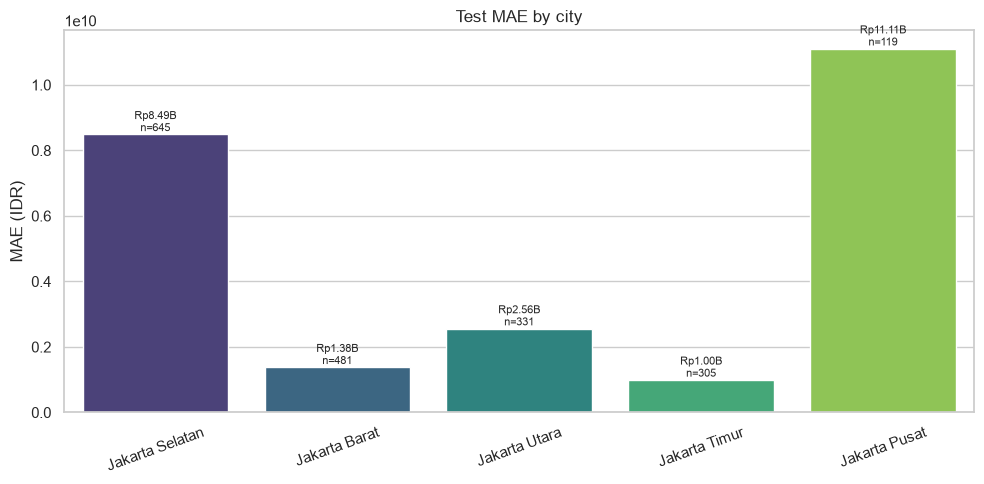

15_error_by_price_band.png


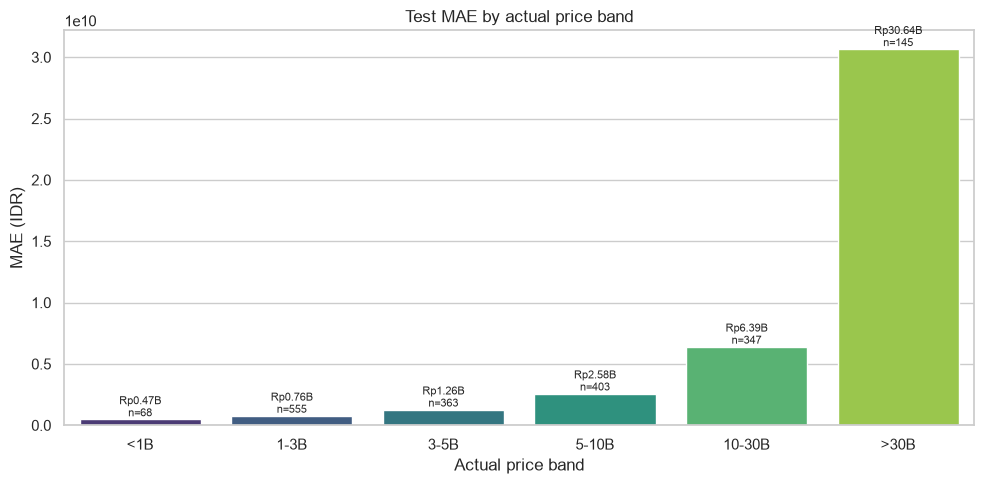

16_feature_importance.png


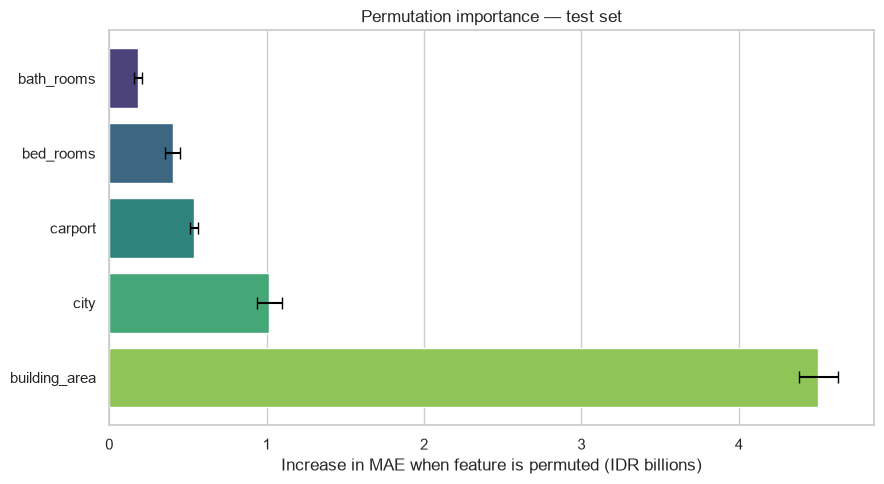

17_model_comparison.png


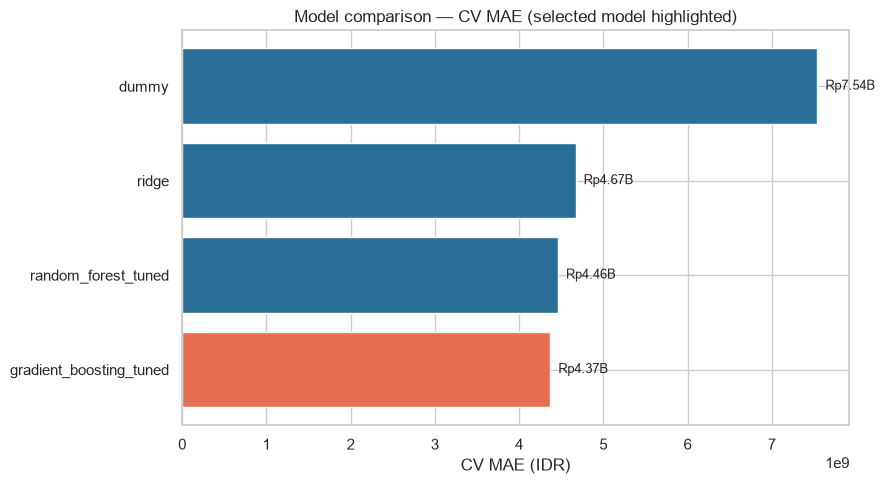

In [7]:
from IPython.display import Image, display as display_image

figure_files = [
    "11_actual_vs_predicted.png",
    "12_residuals.png",
    "14_error_by_city.png",
    "15_error_by_price_band.png",
    "16_feature_importance.png",
    "17_model_comparison.png",
]
for filename in figure_files:
    path = PROJECT_ROOT / "results" / "figures" / filename
    print(filename)
    if path.exists():
        display_image(Image(filename=str(path), width=850))
    else:
        print("  missing; rerun src/train.py --evaluate")

## Interpretation and limitations

- `building_area` is the dominant driver of predictions, followed by `city`; carport and
  room counts contribute less once size and location are known.
- Rupiah MAE is dominated by the luxury segment: absolute errors are much larger for
  listings above Rp10–30 billion. A single aggregate MAE hides this.
- The model is trained on asking prices, not transaction prices, and has no date, street,
  condition, or certificate data.
- Coverage is DKI Jakarta only. The app must not offer cities outside the five training
  cities.
- Test results were produced once after model selection. Re-running the final evaluation
  with `--force` would change that guarantee and should not be done for reporting.